# Como a rede aprende: das contas ao meu projeto Olist

Quero conectar a atualização dos pesos ao treinamento que já executei pelo main.py. Vou separar exemplos didáticos, experimentos na validação e a leitura dos resultados realmente salvos no projeto.

**Ponto de partida:** [02_treinamento_redes_neurais_keras.ipynb](https://github.com/biaag10/machine_learning_projects/tree/develop/deep_learning/notebooks/02_treinamento_redes_neurais_keras.ipynb), do projeto de referência disponibilizado para estudo. Esta versão reorganiza a atividade, explicita decisões e deixa a interpretação dos resultados para a execução neste projeto.

**Como usar:** kernel da `.venv` de `deep_learning`; executar de cima para baixo. As saídas antigas foram removidas. Os resultados abaixo precisam ser gerados nesta execução.


In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
try:
    from IPython.display import display
except ImportError:
    display = print

SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18,
    "axes.prop_cycle": plt.cycler(color=["#0f766e", "#d97706", "#6366f1", "#be185d"]),
})
current = Path.cwd().resolve()
ROOT = next((p for p in [current, *current.parents]
             if (p / "module_deep_learning").is_dir()
             and (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Abra este notebook em deep_learning/notebooks e use a .venv do projeto.")
sys.path.insert(0, str(ROOT))
print("TensorFlow:", tf.__version__)
print("Python:", sys.executable)


def batches(X, y=None, batch_size=256, training=False):
    values = np.asarray(X, dtype="float32")
    tensors = values if y is None else (values, np.asarray(y))
    ds = tf.data.Dataset.from_tensor_slices(tensors)
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    options.threading.max_intra_op_parallelism = 1
    return ds.batch(batch_size).with_options(options).prefetch(1)


TensorFlow: 2.21.0
Python: c:\Users\Rafael Athaliba\Projetos Git\Machine_Learning\Machine_Learning_entrega\deep_learning\.venv\Scripts\python.exe


In [2]:
# Estes limites controlam o tempo dos experimentos deste notebook.
EPOCHS_MANUAL = 200
EPOCHS_TOY = 200
EPOCHS_COMPARE = 10
EPOCHS_OVERFIT = 150
SMALL_SAMPLE = 3000


## 1. Atualizando pesos com GradientTape

Uso os mesmos seis pedidos hipotéticos da atividade introdutória. O GradientTape calcula o gradiente da loss em relação aos parâmetros. Em seguida, atualizo cada parâmetro por $w \leftarrow w - \eta\nabla L$. Esse exemplo não representa o desempenho em pedidos reais.


In [3]:
# Dados da atividade anterior: distância, quantidade de itens e frete (já normalizados)
X_toy = tf.constant(
    [
        [0.20, 0.10, 0.30],
        [0.80, 0.70, 0.90],
        [0.30, 0.20, 0.40],
        [0.90, 0.80, 0.70],
        [0.15, 0.30, 0.20],
        [0.75, 0.60, 0.85],
    ],
    dtype=tf.float32,
)
y_toy = tf.constant([[0], [1], [0], [1], [0], [1]], dtype=tf.float32)


def train_from_scratch(learning_rate, epochs=EPOCHS_MANUAL, seed=SEED):
    # Parâmetros da rede 3 -> 4 -> 1, inicializados aleatoriamente
    rng = tf.random.Generator.from_seed(seed)
    W1 = tf.Variable(rng.normal((3, 4), stddev=0.5))
    b1 = tf.Variable(tf.zeros(4))
    W2 = tf.Variable(rng.normal((4, 1), stddev=0.5))
    b2 = tf.Variable(tf.zeros(1))
    params = [W1, b1, W2, b2]

    loss_fn = keras.losses.BinaryCrossentropy()
    history = []

    for epoch in range(epochs):
        with tf.GradientTape() as tape:
            # FORWARD PASS
            hidden = tf.nn.relu(X_toy @ W1 + b1)       # camada escondida + ReLU
            y_pred = tf.sigmoid(hidden @ W2 + b2)      # saída + sigmoid
            loss = loss_fn(y_toy, y_pred)              # quanto a rede errou

        # BACKPROPAGATION: gradiente da loss em relação a cada parâmetro
        gradients = tape.gradient(loss, params)

        # GRADIENT DESCENT: dá um passo na direção oposta ao gradiente
        for param, grad in zip(params, gradients):
            param.assign_sub(learning_rate * grad)

        history.append(float(loss))

    final_pred = tf.sigmoid(tf.nn.relu(X_toy @ W1 + b1) @ W2 + b2)
    return history, final_pred


manual_history, manual_prediction = train_from_scratch(learning_rate=0.5)
print("Loss antes da primeira atualização:", manual_history[0])
print("BCE após a última atualização:", float(keras.losses.BinaryCrossentropy()(y_toy, manual_prediction)))
display(pd.DataFrame({"real": y_toy.numpy().ravel().astype(int),
                      "escore_final": manual_prediction.numpy().ravel()}))


Loss antes da primeira atualização: 0.694246232509613
BCE após a última atualização: 0.01925591193139553


,real,escore_final
0,0,0.032369
1,1,0.996897
2,0,0.033062
3,1,0.997552
4,0,0.032369
5,1,0.989508


## 2. Testando o tamanho do passo

Mantenho a mesma inicialização e altero somente a taxa de aprendizado. Vou verificar velocidade de redução da loss e oscilações. Não assumo de antemão que a maior taxa será a melhor, nem que Adam sempre vence SGD.


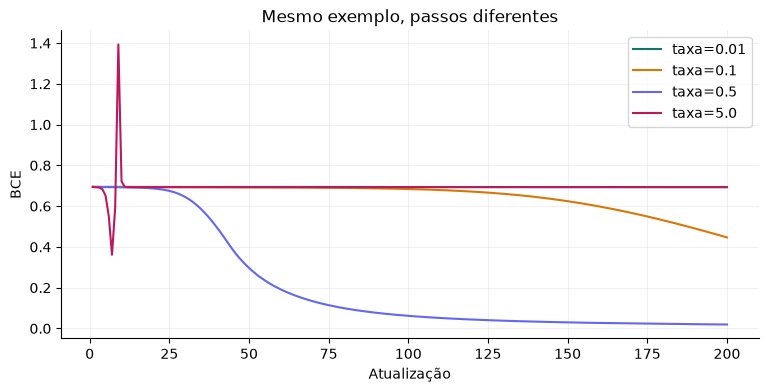

,taxa,loss_inicial,loss_final
0,0.01,0.694246,0.693364
1,0.10,0.694246,0.442014
2,0.50,0.694246,0.019256
3,5.00,0.694246,0.693147


In [4]:
fig, ax = plt.subplots()
lr_rows = []
for rate in (0.01, 0.1, 0.5, 5.0):
    losses, prediction = train_from_scratch(learning_rate=rate)
    ax.plot(np.arange(1, len(losses)+1), losses, label=f"taxa={rate}")
    lr_rows.append({"taxa": rate, "loss_inicial": losses[0],
                    "loss_final": float(keras.losses.BinaryCrossentropy()(y_toy, prediction))})
ax.set(title="Mesmo exemplo, passos diferentes", xlabel="Atualização", ylabel="BCE")
ax.legend(); plt.show(); display(pd.DataFrame(lr_rows))


## 3. A mesma arquitetura com Keras

Agora o fit executa o ciclo de aprendizado. A arquitetura continua 3 → 4 → 1, mas o otimizador Adam não é o mesmo procedimento de descida simples da parte manual. O resultado serve para entender o mecanismo, não para comparar os dois como um experimento controlado de desempenho.


In [5]:
keras.utils.set_random_seed(SEED)
toy_model = keras.Sequential([
    layers.Input(shape=(3,)), layers.Dense(4, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
toy_model.compile(optimizer=keras.optimizers.Adam(0.05), loss="binary_crossentropy", metrics=["accuracy"])
toy_history = toy_model.fit(batches(X_toy, y_toy, batch_size=6, training=True),
                            epochs=EPOCHS_TOY, verbose=0, shuffle=False)
print("Loss final registrada:", toy_history.history["loss"][-1])
print("Escores após treino:", toy_model(X_toy, training=False).numpy().ravel())


Loss final registrada: 0.007450058590620756
Escores após treino: [0.01438665 0.9998615  0.01438665 0.9999255  0.01438665 0.9992952 ]


## 4. Ligando o estudo à base real da Olist

Aqui uso as funções que já construí no projeto, inclusive a imputação dos prazos ausentes. A divisão é 60% treino, 20% validação e 20% teste. O pré-processamento aprende medianas, escala e categorias apenas no treino. O teste não será usado nos experimentos seguintes.


In [6]:
from module_deep_learning.dataset import load_dataset
from module_deep_learning.split import split_data
from module_deep_learning.features import create_preprocessor, transform_features

data = load_dataset()
X_train_df, X_val_df, X_test_df, y_train, y_val, y_test = split_data(data)
preprocessor = create_preprocessor().fit(X_train_df)
X_train = transform_features(preprocessor, X_train_df)
X_val = transform_features(preprocessor, X_val_df)
print("Treino:", X_train.shape, "Validação:", X_val.shape, "Teste reservado:", X_test_df.shape)
counts = y_train.value_counts()
CLASS_WEIGHT = {label: len(y_train)/(2*int(counts[label])) for label in (0, 1)}
print("Pesos calculados no treino:", CLASS_WEIGHT)


2026-10-28 03:02:50.106 | INFO     | module_deep_learning.dataset:load_dataset:24 - Pedidos: 96,456 | Taxa de atraso: 8.11%


Treino: (57873, 80) Validação: (19291, 80) Teste reservado: (19292, 14)
Pesos calculados no treino: {0: 0.5441544276660962, 1: 6.161946337308348}


## 5. Comparando escolhas na validação

Troco a ativação em uma comparação e o otimizador em outra. O orçamento é o mesmo em épocas; isso não garante que todos tenham convergido. Registro o PR-AUC aproximado do Keras **na última época**, sem substituir o modelo que já salvei pelo main.


In [7]:
def build_study_mlp(activation="relu", optimizer="adam", hidden=(64, 32), dropout=0.0, batch_norm=False):
    keras.utils.set_random_seed(SEED)
    network = keras.Sequential([layers.Input(shape=(X_train.shape[1],))])
    for units in hidden:
        network.add(layers.Dense(units))
        if batch_norm:
            network.add(layers.BatchNormalization())
        network.add(layers.Activation(activation))
        if dropout:
            network.add(layers.Dropout(dropout))
    network.add(layers.Dense(1, activation="sigmoid"))
    optim = keras.optimizers.Adam(0.001) if optimizer == "adam" else keras.optimizers.SGD(0.01)
    network.compile(optimizer=optim, loss="binary_crossentropy", metrics=[
        keras.metrics.AUC(curve="PR", name="pr_auc"), keras.metrics.AUC(curve="ROC", name="roc_auc")])
    return network


def fit_study(network, X, y, epochs, callbacks=None):
    counts = np.bincount(np.asarray(y, dtype=int), minlength=2)
    if (counts == 0).any():
        raise ValueError("O estudo precisa de ambas as classes no conjunto de treino.")
    weights = {i: len(y)/(2*int(counts[i])) for i in (0, 1)}
    return network.fit(batches(X, y, training=True), validation_data=batches(X_val, y_val),
                       epochs=epochs, class_weight=weights, callbacks=callbacks or [],
                       verbose=0, shuffle=False)

comparison_rows = []
for activation in ("relu", "tanh", "sigmoid"):
    history = fit_study(build_study_mlp(activation=activation), X_train, y_train, EPOCHS_COMPARE)
    comparison_rows.append({"grupo": "ativação", "opcao": activation,
                            "val_pr_auc_ultima_epoca": history.history["val_pr_auc"][-1]})
for optimizer in ("sgd", "adam"):
    history = fit_study(build_study_mlp(optimizer=optimizer), X_train, y_train, EPOCHS_COMPARE)
    comparison_rows.append({"grupo": "otimizador", "opcao": optimizer,
                            "val_pr_auc_ultima_epoca": history.history["val_pr_auc"][-1]})
comparison = pd.DataFrame(comparison_rows)
display(comparison)
REPORT = ROOT / "reports" / "notebooks"
REPORT.mkdir(parents=True, exist_ok=True)
comparison.to_csv(REPORT / "keras_comparacoes.csv", index=False)


,grupo,opcao,val_pr_auc_ultima_epoca
0,ativação,relu,0.234510
1,ativação,tanh,0.234043
2,ativação,sigmoid,0.226040
3,otimizador,sgd,0.187830
4,otimizador,adam,0.234510


## 6. Observando regularização com poucos pedidos

Comparo uma rede maior com uma versão que combina Dropout, Batch Normalization e parada antecipada. Como várias decisões mudam juntas, não atribuo uma eventual melhora a um único componente. O overfitting precisa ser observado nos resultados; ele não é garantido só por escolher uma rede grande.

A loss de treino é ponderada por classe e a de validação não. Essa diferença impede interpretar toda distância entre essas duas curvas como overfitting.


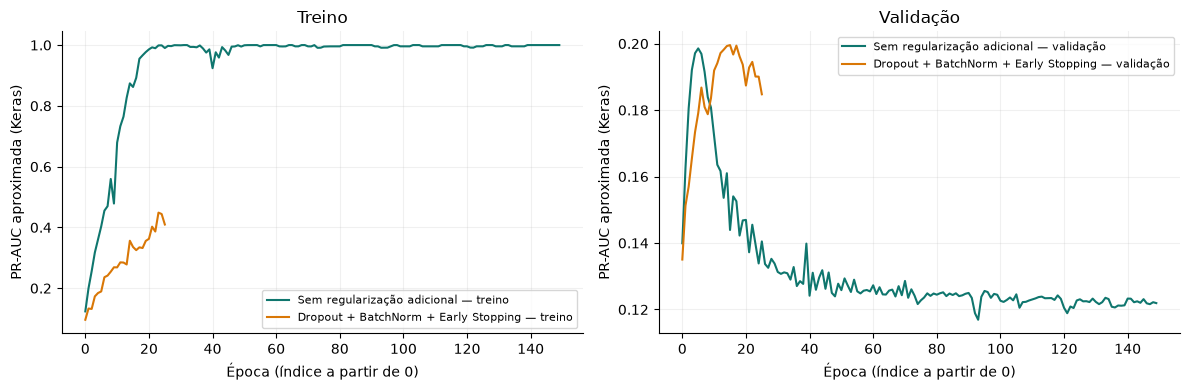

In [8]:
from sklearn.model_selection import train_test_split
size = min(SMALL_SAMPLE, len(y_train))
if size == len(y_train):
    small_idx = np.arange(len(y_train))
else:
    small_idx, _ = train_test_split(np.arange(len(y_train)), train_size=size,
                                    stratify=y_train, random_state=SEED)
X_small, y_small = X_train[small_idx], y_train.iloc[small_idx]
history_plain = fit_study(build_study_mlp(hidden=(256,128,64)), X_small, y_small, EPOCHS_OVERFIT)
history_regularized = fit_study(
    build_study_mlp(hidden=(256,128,64), dropout=0.3, batch_norm=True),
    X_small, y_small, EPOCHS_OVERFIT,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=10, restore_best_weights=True)],
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for history, label in [(history_plain, "Sem regularização adicional"),
                        (history_regularized, "Dropout + BatchNorm + Early Stopping")]:
    axes[0].plot(history.history["pr_auc"], label=label+" — treino")
    axes[1].plot(history.history["val_pr_auc"], label=label+" — validação")
axes[0].set(title="Treino", ylabel="PR-AUC aproximada (Keras)")
axes[1].set(title="Validação", ylabel="PR-AUC aproximada (Keras)")
for ax in axes:
    ax.set_xlabel("Época (índice a partir de 0)"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()


## 7. Minha execução já salva pelo main.py

A implementação modular já treinou a MLP regularizada. Vou ler seus metadados e métricas, sem repetir o treinamento nem substituir o checkpoint. Os experimentos anteriores são estudos na validação e não alteram esse modelo.

O teste já foi consultado no Olist e nesta etapa; não o apresento como uma avaliação inédita. O PR-AUC aproximado do Keras usado para acompanhar épocas também não é exatamente a Average Precision do scikit-learn no relatório final.


In [9]:
metadata_path = ROOT / "models" / "mlp_metadata.json"
metrics_path = ROOT / "reports" / "mlp_test_metrics.json"
if not metadata_path.is_file() or not metrics_path.is_file():
    raise FileNotFoundError("Execute primeiro: uv run python -m module_deep_learning.main")
metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
print("Épocas executadas:", metadata["epochs_run"], "| Melhor época:", metadata["best_epoch"])
display(pd.DataFrame([metrics["metrics"]], index=["MLP salva pelo main"]))
print("Matriz de confusão:", metrics["confusion_matrix"])


Épocas executadas: 24 | Melhor época: 19


,accuracy,precision,recall,f1,roc_auc,average_precision
MLP salva pelo main,0.692308,0.166692,0.698403,0.269146,0.762847,0.239761


Matriz de confusão: {'tn': 12263, 'fp': 5464, 'fn': 472, 'tp': 1093}


## Minhas conclusões após executar

- Qual configuração teve maior métrica de validação com o orçamento escolhido?
- A regularização alterou a distância entre treino e validação? Como?
- Como os resultados do modelo salvo se relacionam com os alertas falsos e os atrasos não detectados?
- Que comparações exigiriam novas sementes e um novo conjunto reservado?

Não vou afirmar que uma ativação, um otimizador ou uma arquitetura sempre vence. Os resultados dependem do conjunto, da configuração e do critério de comparação.
